# F3 · Medición de eficiencia

**Proyecto:** Concentración del gasto público en salud · Región de Valparaíso · ChileCompra  
**Fase 3 · Sumativa 2** · MCDI500 Programación para la Ciencia de Datos · Grupo 5

Comparamos tres pares de implementaciones de operaciones reales del pipeline,
midiendo tiempo con `timeit` y memoria con `tracemalloc`.
El protocolo sigue la Figura 4 de la guía:

1. Medir con el tamaño real de los datos (`data/raw/`).
2. Verificar que las dos versiones producen el mismo resultado antes de medir.
3. Medir tiempo: `timeit.repeat`, 7 repeticiones, conservar el mínimo.
4. Medir memoria: `tracemalloc`.
5. Interpretar: diferencia de tiempo, costo de memoria y qué significa con este volumen.

Las funciones de medición y las implementaciones están en
`src/pipeline/medicion.py` para no duplicar código con `tests/test_eficiencia.py`.
El comportamiento con tamaños crecientes se evalúa por separado en
[`F3_escalamiento.ipynb`](F3_escalamiento.ipynb).


## Carga de datos reales


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pipeline import config, ordenes
from pipeline.medicion import (
    medir,
    parse_amount_apply, parse_amount_vectorizado,
    monto_por_proveedor_bucle, monto_por_proveedor_groupby,
    classify_modality_apply, classify_modality_select,
    REPETICIONES,
)

# Paleta de colores compartida
ROJO  = '#c62828'; VERDE  = '#2e7d32'
FROJO = '#ffebee'; FVERDE = '#e8f5e9'

# Funciones de formato para las interpretaciones dinamicas
def _vel(factor):
    if factor >= 2:     return f'{factor:.0f}x mas rapida'
    elif factor >= 1.1: return f'{factor:.1f}x mejor'
    else:               return f'sin diferencia apreciable ({factor:.2f}x)'

def _mem(ratio):
    if ratio < 0.9:     return f'{ratio:.2f}x menos memoria (ventaja adicional)'
    elif ratio <= 1.25: return f'memoria similar ({ratio:.2f}x)'
    else:               return f'{ratio:.2f}x mas memoria (costo moderado)'

def grafico_comp(titulo_fig, etiquetas, tiempos, memorias, num_fig):
    """Genera un grafico de 2 paneles (tiempo | memoria) para una comparacion."""
    fig, (ax_t, ax_m) = plt.subplots(1, 2, figsize=(11, 4))
    fig.patch.set_facecolor('#fafafa')
    fig.suptitle(titulo_fig, fontsize=12, fontweight='bold', y=1.02)

    for ax, valores, unidad, titulo_panel in [
        (ax_t, tiempos,  'ms',  'Tiempo de ejecucion (menor es mejor)'),
        (ax_m, memorias, 'KiB', 'Pico de memoria (menor es mejor)'),
    ]:
        bars = ax.bar(etiquetas, valores, color=[ROJO, VERDE],
                      edgecolor='white', width=0.5, zorder=3)
        for i, f in enumerate([FROJO, FVERDE]):
            ax.axvspan(i - 0.45, i + 0.45, color=f, zorder=0, alpha=0.6)
        for b, v in zip(bars, valores):
            ax.text(b.get_x() + b.get_width() / 2,
                    b.get_height() + max(valores) * 0.02,
                    f'{v:.1f} {unidad}',
                    ha='center', va='bottom', fontsize=10, fontweight='bold')
        # badge con resultado
        ratio = valores[1] / valores[0]
        if unidad == 'ms':
            badge = _vel(valores[0] / valores[1])
            bc    = VERDE if ratio < 0.9 else ('#388e3c' if ratio < 1 else '#f57f17')
        else:
            badge = _mem(ratio)
            bc    = VERDE if ratio < 0.9 else ('#f57f17' if ratio <= 1.25 else '#e65100')
        ax.text(0.5, 0.97, badge, transform=ax.transAxes,
                ha='center', va='top', fontsize=9, fontweight='bold', color='white',
                bbox=dict(boxstyle='round,pad=0.4', facecolor=bc, edgecolor='none'))
        ax.set_title(titulo_panel, fontsize=10, pad=10)
        ax.set_ylim(0, max(valores) * 1.55)
        ax.tick_params(axis='x', labelsize=10)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_facecolor('#fafafa')
        ax.yaxis.grid(True, linestyle='--', alpha=0.4, zorder=0)
        ax.set_axisbelow(True)
        ax.set_ylabel(unidad, fontsize=9)

    # leyenda global
    from matplotlib.patches import Patch
    fig.legend(
        handles=[Patch(color=ROJO, label='Referencia (no usada en produccion)'),
                 Patch(color=VERDE, label='Pipeline real')],
        loc='lower center', ncol=2, fontsize=9, framealpha=0.85,
        bbox_to_anchor=(0.5, -0.12),
    )
    plt.tight_layout()
    plt.show()

# Datos reales
raw            = ordenes.load_orders(config.RAW_DATA_DIR)
montos_texto   = raw['MontoTotalOC_PesosChilenos']
typed          = ordenes.cast_types(ordenes.normalize_missing(raw))
clasif         = ordenes.classify_modality(typed)
ordenes_reales = ordenes.aggregate_orders(clasif)
lineas_tipadas = typed

print(f'Lineas en raw:      {len(raw):>7,}')
print(f'Ordenes agregadas:  {len(ordenes_reales):>7,}')
print(f'Proveedores unicos: {ordenes_reales["CodigoProveedor"].nunique():>7,}')


Lineas en raw:       25,880
Ordenes agregadas:   10,285
Proveedores unicos:   2,317


---
## Comparacion 1 · `apply` vs. `str.replace + pd.to_numeric`

**Operacion:** convertir montos con coma decimal (`'3401030,71'` → `3401030.71`)
sobre las **25 880 lineas** reales del dataset.

| Version | Implementacion |
|---|---|
| A (referencia) | `Series.apply(lambda ...)` |
| B (pipeline real) | `str.replace` + `pd.to_numeric` |


In [2]:
res_a = parse_amount_apply(montos_texto)
res_b = parse_amount_vectorizado(montos_texto)
assert res_a.equals(res_b)
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [3]:
t_a, mem_a = medir(parse_amount_apply,       montos_texto)
t_b, mem_b = medir(parse_amount_vectorizado, montos_texto)

print(f'Version A (apply):       {t_a*1000:6.1f} ms   {mem_a:6.0f} KiB')
print(f'Version B (vectorizada): {t_b*1000:6.1f} ms   {mem_b:6.0f} KiB')
print(f'Factor tiempo A/B:       {t_a/t_b:6.2f}x')
print(f'Factor memoria B/A:      {mem_b/mem_a:6.2f}x')


Version A (apply):         17.6 ms     2074 KiB
Version B (vectorizada):   21.9 ms     2191 KiB
Factor tiempo A/B:         0.80x
Factor memoria B/A:        1.06x


In [4]:
resumen_1 = pd.DataFrame({
    'Version':              ['A · apply', 'B · vectorizada (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_a*1000, 1), round(t_b*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_a, 0),    round(mem_b, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_1


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · apply,17.6,2074.0,No
1,B · vectorizada (pipeline),21.9,2191.0,Si


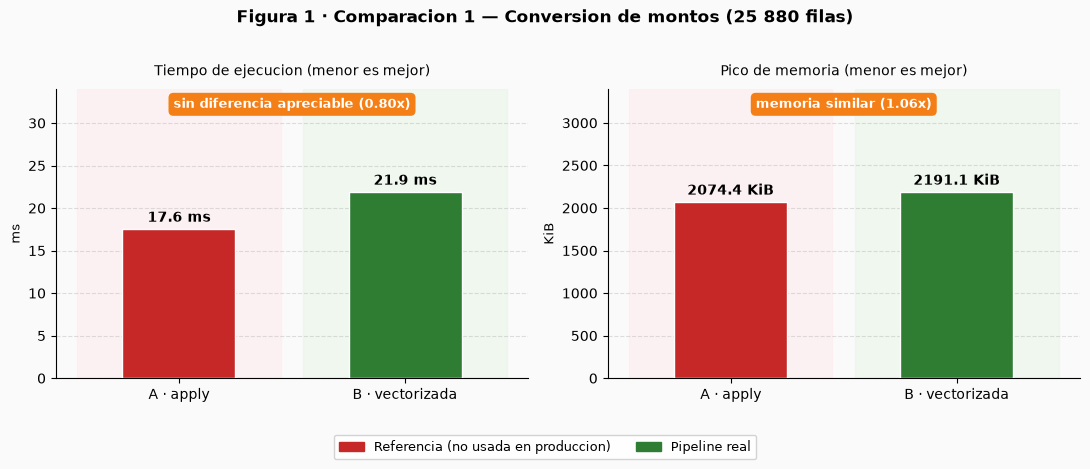

In [5]:
grafico_comp(
    'Figura 1 · Comparacion 1 — Conversion de montos (25 880 filas)',
    etiquetas=['A · apply', 'B · vectorizada'],
    tiempos  =[t_a*1000, t_b*1000],
    memorias =[mem_a, mem_b],
    num_fig  =1,
)


In [6]:
display(Markdown(f'''
### Interpretacion · Comparacion 1

- **apply:** `{t_a*1000:.1f} ms · {mem_a:.0f} KiB` &nbsp;|&nbsp;
  **vectorizada:** `{t_b*1000:.1f} ms · {mem_b:.0f} KiB`
- Tiempo: {_vel(t_a/t_b)} &nbsp;|&nbsp; Memoria: {_mem(mem_b/mem_a)}

En esta ejecucion sobre los datos reales, apply y `str.replace + pd.to_numeric`
tuvieron tiempos similares; apply resulto ligeramente mas rapida. Esta conclusion
se limita al volumen medido aqui. El comportamiento con otros tamanios se presenta
en `F3_escalamiento.ipynb`, sin extrapolar este resultado.
**Medir antes de afirmar**: la hipotesis previa no se cumple, y eso es un resultado valido.
'''))



### Interpretacion · Comparacion 1

- **apply:** `17.6 ms · 2074 KiB` &nbsp;|&nbsp;
  **vectorizada:** `21.9 ms · 2191 KiB`
- Tiempo: sin diferencia apreciable (0.80x) &nbsp;|&nbsp; Memoria: memoria similar (1.06x)

En esta ejecucion sobre los datos reales, apply y `str.replace + pd.to_numeric`
tuvieron tiempos similares; apply resulto ligeramente mas rapida. Esta conclusion
se limita al volumen medido aqui. El comportamiento con otros tamanios se presenta
en `F3_escalamiento.ipynb`, sin extrapolar este resultado.
**Medir antes de afirmar**: la hipotesis previa no se cumple, y eso es un resultado valido.


---
## Comparacion 2 · `iterrows` vs. `groupby`

**Operacion:** sumar `MontoTotalOC_PesosChilenos` por `periodo` y `CodigoProveedor`
sobre las **10 285 ordenes** reales (una fila por orden, 2 317 proveedores unicos).

| Version | Implementacion |
|---|---|
| A (referencia) | `iterrows` + diccionario acumulador |
| B (pipeline real) | `groupby().sum()` — arrays NumPy en C |


In [7]:
serie_a = monto_por_proveedor_bucle(ordenes_reales).sort_index()
serie_b = monto_por_proveedor_groupby(ordenes_reales).sort_index()
serie_a.index = pd.MultiIndex.from_tuples(serie_a.index)
assert (serie_a - serie_b).abs().max() < 1e-6
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [8]:
t_c, mem_c = medir(monto_por_proveedor_bucle,   ordenes_reales)
t_d, mem_d = medir(monto_por_proveedor_groupby, ordenes_reales)

print(f'Version A (iterrows): {t_c*1000:7.1f} ms   {mem_c:6.0f} KiB')
print(f'Version B (groupby):  {t_d*1000:7.1f} ms   {mem_d:6.0f} KiB')
print(f'Factor tiempo A/B:    {t_c/t_d:7.1f}x')
print(f'Factor memoria B/A:   {mem_d/mem_c:7.2f}x')


Version A (iterrows):   758.4 ms     3058 KiB
Version B (groupby):      4.5 ms      795 KiB
Factor tiempo A/B:      169.4x
Factor memoria B/A:      0.26x


In [9]:
resumen_2 = pd.DataFrame({
    'Version':              ['A · iterrows', 'B · groupby (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_c*1000, 1), round(t_d*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_c, 0),    round(mem_d, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_2


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · iterrows,758.4,3058.0,No
1,B · groupby (pipeline),4.5,795.0,Si


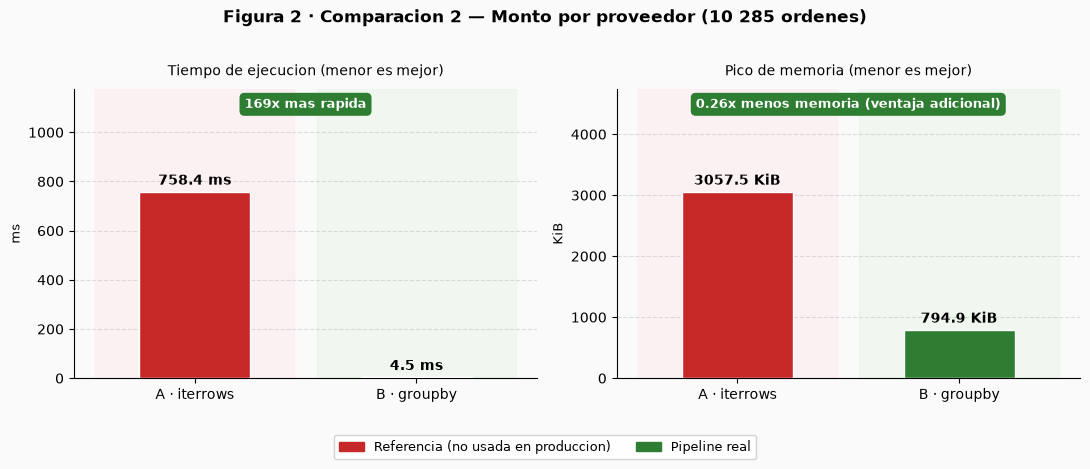

In [10]:
grafico_comp(
    'Figura 2 · Comparacion 2 — Monto por proveedor (10 285 ordenes)',
    etiquetas=['A · iterrows', 'B · groupby'],
    tiempos  =[t_c*1000, t_d*1000],
    memorias =[mem_c, mem_d],
    num_fig  =2,
)


In [11]:
display(Markdown(f'''
### Interpretacion · Comparacion 2

- **iterrows:** `{t_c*1000:.1f} ms · {mem_c:.0f} KiB` &nbsp;|&nbsp;
  **groupby:** `{t_d*1000:.1f} ms · {mem_d:.0f} KiB`
- Tiempo: {_vel(t_c/t_d)} &nbsp;|&nbsp; Memoria: {_mem(mem_d/mem_c)}

`iterrows` convierte cada fila en un objeto `Series` completo antes de entregarla al
bucle. La implementacion medida con `groupby` no construye esos objetos por fila.

La comparacion se limita a las dos implementaciones medidas: `iterrows` y `groupby`.
El pipeline elige `groupby` porque produjo el mismo resultado en menos tiempo y
con menor uso de memoria en esta ejecucion.
'''))



### Interpretacion · Comparacion 2

- **iterrows:** `758.4 ms · 3058 KiB` &nbsp;|&nbsp;
  **groupby:** `4.5 ms · 795 KiB`
- Tiempo: 169x mas rapida &nbsp;|&nbsp; Memoria: 0.26x menos memoria (ventaja adicional)

`iterrows` convierte cada fila en un objeto `Series` completo antes de entregarla al
bucle. La implementacion medida con `groupby` no construye esos objetos por fila.

La comparacion se limita a las dos implementaciones medidas: `iterrows` y `groupby`.
El pipeline elige `groupby` porque produjo el mismo resultado en menos tiempo y
con menor uso de memoria en esta ejecucion.


---
## Comparacion 3 · `apply` por fila vs. `np.select` (classify_modality)

**Operacion:** asignar la modalidad de compra a cada una de las **25 880 lineas**.

| Version | Implementacion |
|---|---|
| A (referencia) | `DataFrame.apply(func, axis=1)` — un objeto Python por fila |
| B (pipeline real) | `np.select(conditions, choices)` — mascaras NumPy |

Esta es la comparacion mas nitida: operacion booleana donde la vectorizacion
si elimina el bucle de Python.


In [12]:
res_c = classify_modality_apply(lineas_tipadas)
res_d = classify_modality_select(lineas_tipadas)
assert res_c.equals(res_d)
print('OK: ambas versiones producen el mismo resultado.')


OK: ambas versiones producen el mismo resultado.


In [13]:
t_e, mem_e = medir(classify_modality_apply,  lineas_tipadas)
t_f, mem_f = medir(classify_modality_select, lineas_tipadas)

print(f'Version A (apply):     {t_e*1000:7.1f} ms   {mem_e:6.0f} KiB')
print(f'Version B (np.select): {t_f*1000:7.1f} ms   {mem_f:6.0f} KiB')
print(f'Factor tiempo A/B:     {t_e/t_f:7.1f}x')
print(f'Factor memoria B/A:    {mem_f/mem_e:7.2f}x')


Version A (apply):       470.6 ms    33804 KiB
Version B (np.select):     9.3 ms     4716 KiB
Factor tiempo A/B:        50.4x
Factor memoria B/A:       0.14x


In [14]:
resumen_3 = pd.DataFrame({
    'Version':              ['A · apply por fila', 'B · np.select (pipeline)'],
    'Tiempo minimo (ms)':   [round(t_e*1000, 1), round(t_f*1000, 1)],
    'Pico de memoria (KiB)':[round(mem_e, 0),    round(mem_f, 0)],
    'Pipeline real':        ['No', 'Si'],
})
resumen_3


,Version,Tiempo minimo (ms),Pico de memoria (KiB),Pipeline real
0,A · apply por fila,470.6,33804.0,No
1,B · np.select (pipeline),9.3,4716.0,Si


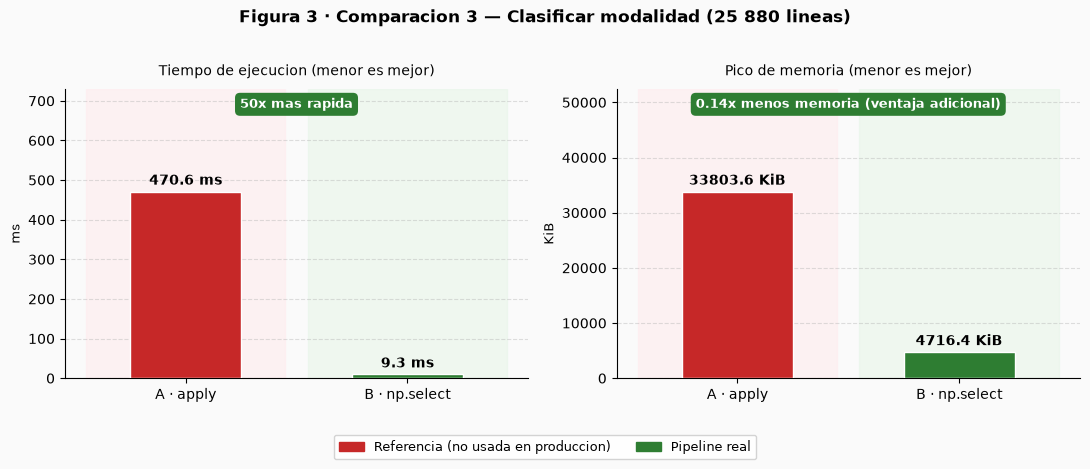

In [15]:
grafico_comp(
    'Figura 3 · Comparacion 3 — Clasificar modalidad (25 880 lineas)',
    etiquetas=['A · apply', 'B · np.select'],
    tiempos  =[t_e*1000, t_f*1000],
    memorias =[mem_e, mem_f],
    num_fig  =3,
)


In [16]:
display(Markdown(f'''
### Interpretacion · Comparacion 3

- **apply:** `{t_e*1000:.1f} ms · {mem_e:.0f} KiB` &nbsp;|&nbsp;
  **np.select:** `{t_f*1000:.1f} ms · {mem_f:.0f} KiB`
- Tiempo: {_vel(t_e/t_f)} &nbsp;|&nbsp; Memoria: {_mem(mem_f/mem_e)}

`apply(axis=1)` construye un objeto por cada una de las 25 880 lineas.
`np.select` evalua las cuatro condiciones como mascaras booleanas sobre columnas
completas (arrays NumPy en C) y elige el valor en un solo recorrido.

Esta es la comparacion donde la vectorizacion rindio con mayor claridad en esta ejecucion:
**{_vel(t_e/t_f)} y {_mem(mem_f/mem_e)}** sobre {len(lineas_tipadas):,} lineas.
El cuello de botella aqui es el bucle de Python, no el parseo de strings
como en la Comparacion 1.
'''))



### Interpretacion · Comparacion 3

- **apply:** `470.6 ms · 33804 KiB` &nbsp;|&nbsp;
  **np.select:** `9.3 ms · 4716 KiB`
- Tiempo: 50x mas rapida &nbsp;|&nbsp; Memoria: 0.14x menos memoria (ventaja adicional)

`apply(axis=1)` construye un objeto por cada una de las 25 880 lineas.
`np.select` evalua las cuatro condiciones como mascaras booleanas sobre columnas
completas (arrays NumPy en C) y elige el valor en un solo recorrido.

Esta es la comparacion donde la vectorizacion rindio con mayor claridad en esta ejecucion:
**50x mas rapida y 0.14x menos memoria (ventaja adicional)** sobre 25 880 lineas.
El cuello de botella aqui es el bucle de Python, no el parseo de strings
como en la Comparacion 1.


---
## Resumen general y conclusion


In [17]:
resumen_general = pd.DataFrame({
    'Comparacion': [
        '1A · apply', '1B · vectorizada (pipeline)',
        '2A · iterrows', '2B · groupby (pipeline)',
        '3A · apply por fila', '3B · np.select (pipeline)',
    ],
    'Operacion': [
        'Conv. montos (25 880 filas)', 'Conv. montos (25 880 filas)',
        'Monto proveedor (10 285 ord.)', 'Monto proveedor (10 285 ord.)',
        'Clasif. modalidad (25 880 lin.)', 'Clasif. modalidad (25 880 lin.)',
    ],
    'Tiempo (ms)': [
        round(t_a*1000,1), round(t_b*1000,1),
        round(t_c*1000,1), round(t_d*1000,1),
        round(t_e*1000,1), round(t_f*1000,1),
    ],
    'Memoria (KiB)': [
        round(mem_a,0), round(mem_b,0),
        round(mem_c,0), round(mem_d,0),
        round(mem_e,0), round(mem_f,0),
    ],
    'Pipeline real': ['No','Si','No','Si','No','Si'],
})
resumen_general


,Comparacion,Operacion,Tiempo (ms),Memoria (KiB),Pipeline real
0,1A · apply,Conv. montos (25 880 filas),17.6,2074.0,No
1,1B · vectorizada (pipeline),Conv. montos (25 880 filas),21.9,2191.0,Si
2,2A · iterrows,Monto proveedor (10 285 ord.),758.4,3058.0,No
3,2B · groupby (pipeline),Monto proveedor (10 285 ord.),4.5,795.0,Si
4,3A · apply por fila,Clasif. modalidad (25 880 lin.),470.6,33804.0,No
5,3B · np.select (pipeline),Clasif. modalidad (25 880 lin.),9.3,4716.0,Si


In [18]:
display(Markdown(f'''
### Conclusion general

Las tres comparaciones ilustran el patron central: **medir antes de afirmar**.

| Comparacion | Factor tiempo | Factor memoria |
|---|---|---|
| Comp. 1 · Conv. montos | {_vel(t_a/t_b)} | {_mem(mem_b/mem_a)} |
| Comp. 2 · Monto proveedor | {_vel(t_c/t_d)} | {_mem(mem_d/mem_c)} |
| Comp. 3 · Clasif. modalidad | {_vel(t_e/t_f)} | {_mem(mem_f/mem_e)} |

- **Comp. 1:** en este conjunto, la version vectorizada no fue mas rapida;
  la hipotesis previa no se cumple — ese es el resultado valido.
- **Comp. 2:** `groupby` supera a `iterrows` por un factor muy grande
  en la comparacion realizada. No se evaluaron otras variantes de bucle.
- **Comp. 3:** `np.select` es {_vel(t_e/t_f)} y usa {_mem(mem_f/mem_e)}
  respecto a `apply` — la mejora mas nitida y consistente de las tres.

El pipeline usa `groupby` y `np.select` porque estas mediciones los respaldan.
Las conclusiones se limitan a los pares implementados y al volumen medido aqui;
el analisis por tamanio se encuentra en `F3_escalamiento.ipynb`.
'''))



### Conclusion general

Las tres comparaciones ilustran el patron central: **medir antes de afirmar**.

| Comparacion | Factor tiempo | Factor memoria |
|---|---|---|
| Comp. 1 · Conv. montos | sin diferencia apreciable (0.80x) | memoria similar (1.06x) |
| Comp. 2 · Monto proveedor | 169x mas rapida | 0.26x menos memoria (ventaja adicional) |
| Comp. 3 · Clasif. modalidad | 50x mas rapida | 0.14x menos memoria (ventaja adicional) |

- **Comp. 1:** en este conjunto, la version vectorizada no fue mas rapida;
  la hipotesis previa no se cumple — ese es el resultado valido.
- **Comp. 2:** `groupby` supera a `iterrows` por un factor muy grande
  en la comparacion realizada. No se evaluaron otras variantes de bucle.
- **Comp. 3:** `np.select` es 50x mas rapida y usa 0.14x menos memoria (ventaja adicional)
  respecto a `apply` — la mejora mas nitida y consistente de las tres.

El pipeline usa `groupby` y `np.select` porque estas mediciones los respaldan.
Las conclusiones se limitan a los pares implementados y al volumen medido aqui;
el analisis por tamanio se encuentra en `F3_escalamiento.ipynb`.
